# CIFAR-100: EmbeddingGemma 2, UMAP, and IMSTE

Load the cached EmbeddingGemma 2 image vectors, fit UMAP and IMSTE, and compare their 2D layouts. Points are colored hierarchically: each coarse superclass has its own hue, and its five fine classes use shades of that hue. The compact key below the plots names all 100 fine classes.

Run [prepare_cifar100_dataset.ipynb](dataset_setup/prepare_cifar100_dataset.ipynb) first. The dataset notebook downloads CIFAR-100 and caches the image vectors.

In [13]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np

REPO_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
        and (path / "imste" / "__init__.py").is_file()
    ),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "data" / "cifar100"
MANIFEST_PATH = DATA_DIR / "cache" / "embeddinggemma2_cifar100_manifest.json"
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {MANIFEST_PATH}. Run dataset_setup/prepare_cifar100_dataset.ipynb first."
    )

manifest = json.loads(MANIFEST_PATH.read_text())
EMBEDDING_PATH = MANIFEST_PATH.parent / manifest["embedding_file"]
with np.load(EMBEDDING_PATH, allow_pickle=False) as saved:
    X = saved["embeddings"]
    fine_labels = saved["fine_labels"]
    coarse_labels = saved["coarse_labels"]
    sample_indices = saved["indices"]
    fine_to_coarse = saved["fine_to_coarse"]
    fine_names = saved["fine_names"].tolist()
    coarse_names = saved["coarse_names"].tolist()

if X.ndim != 2 or X.shape[0] != len(fine_labels) or len(fine_labels) != len(coarse_labels):
    raise ValueError(f"Unexpected embedding and label shapes: {X.shape}, {fine_labels.shape}, {coarse_labels.shape}")
if len(fine_names) != 100 or len(coarse_names) != 20 or len(fine_to_coarse) != 100:
    raise ValueError("Expected the CIFAR-100 100-fine-class/20-superclass taxonomy.")
if not np.isfinite(X).all():
    raise ValueError("The cached vectors contain NaN or infinite values.")

actual_fingerprint = hashlib.sha256(
    np.ascontiguousarray(X).view(np.uint8)
).hexdigest()
if actual_fingerprint != manifest["vector_sha256"]:
    raise ValueError("The cached vectors do not match the manifest fingerprint.")
if not np.array_equal(fine_to_coarse[fine_labels], coarse_labels):
    raise ValueError("Fine and coarse labels disagree with the saved CIFAR-100 taxonomy.")

print("Dataset:", manifest["dataset"])
print("Encoder:", manifest["model_id"])
print("Embedding matrix:", X.shape, X.dtype)
print("Fine classes:", len(fine_names), "| superclasses:", len(coarse_names))
print("Loaded from:", EMBEDDING_PATH)


Dataset: CIFAR-100 train
Encoder: google/embeddinggemma-2
Embedding matrix: (50000, 768) float32
Fine classes: 100 | superclasses: 20
Loaded from: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/cifar100/cache/cifar100_train_500_per_fine_class_seed42_embeddinggemma_2.npz


## Fit UMAP and IMSTE

The EmbeddingGemma 2 vectors are already L2-normalized. These settings match the other image-embedding comparison notebooks; IMSTE keeps the project defaults apart from the four main experiment controls.

In [14]:
import time
import umap

UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 15,
    "min_dist": 0.1,
    "metric": "euclidean",
    "init": "recursive",
    "recursive_coarsening_ratio": 4,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": int(manifest["random_state"]),
    "n_epochs": 200,
    "repulsion_strength": 1.0,
    "n_jobs": 1,
    "verbose": True,
}

umap_started = time.perf_counter()
Z_umap = umap.UMAP(**UMAP_SETTINGS).fit_transform(X)
umap_seconds = time.perf_counter() - umap_started
print(f"UMAP fit in {umap_seconds / 60:.1f} min")
print("UMAP coordinates:", Z_umap.shape)


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, n_jobs=1, nearest_neighbor_backend='rinnd', random_state=42, verbose=True)
Tue Nov 17 07:50:34 2026 Construct fuzzy simplicial set
Tue Nov 17 07:50:34 2026 Finding Nearest Neighbors
Tue Nov 17 07:50:34 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 9619 leaves...
Running NN-descent for up to 16 iterations...
Iteration 1: 362449 updates
Iteration 2: 146576 updates
Iteration 3: 29229 updates
Iteration 4: 6216 updates
Iteration 5: 1524 updates
Iteration 6: 390 updates
Converged after 6 iterations

=== Timing Breakdown ===
Forest building:    1459.435ms
Leaf initialization:1316.764ms
Candidate building:  182.014ms (6 iters)
Update iterations:  2809.209ms (6 iters)
Total measured:     5767.422ms
Tue Nov 17 07:50:40 2026 Finished Nearest Neighbor Search
Tue Nov 17 07:50:40 2026 Construct embedding
Tue Nov 17 07:50:40 2026 Recursive initialization: coarsening 50000 nodes int

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Tue Nov 17 07:50:40 2026 Recursive initialization: coarsening 12500 nodes into about 3125 parts
Tue Nov 17 07:50:40 2026 Recursive initialization: coarsening 3125 nodes into about 781 parts


Init recursion depth 3:   0%|          | 0/98 [00:00<?, ?it/s]

Init recursion depth 2:   0%|          | 0/70 [00:00<?, ?it/s]

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: divide by zero encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: overflow encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: invalid value encountered in matmul
  result = result @ rotation


Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Tue Nov 17 07:50:40 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Tue Nov 17 07:50:47 2026 Finished embedding
UMAP fit in 0.2 min
UMAP coordinates: (50000, 2)


In [43]:
import time
from imste import IteratedMinimumSpanningTreeEmbedder

IMSTE_SETTINGS = {
    "n_msts": 64,
    "n_epochs": 200,
    "random_state": int(manifest["random_state"]),
    "gravity_strength": 0.075,
    "mean_shift_iterations": 2,
}

imste_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_SETTINGS)
Z_imste = imste_estimator.fit_transform(X)
imste_seconds = imste_estimator.imste_fit_time_
gravity_seconds = imste_estimator.gravity_time_
mean_shift_seconds = imste_estimator.mean_shift_time_
print(
    f"IMSTE fit {imste_seconds:.1f}s; gravity {gravity_seconds:.1f}s; "
    f"mean shift {mean_shift_seconds:.1f}s"
)
print("IMSTE coordinates:", Z_imste.shape)


IMSTE fit 51.7s; gravity 3.1s; mean shift 0.5s
IMSTE coordinates: (50000, 2)


## Compare the layouts

The first view pairs UMAP and IMSTE side by side. Animal and people superclasses use related warm reds and oranges; plants and natural scenes use greens and blues; household, vehicle, and built-environment superclasses use neutral grays. The five fine classes in each superclass are different shades of its superclass color. The interactive Plotly view below uses the final IMSTE layout; hover points for both labels or toggle a superclass from the legend.


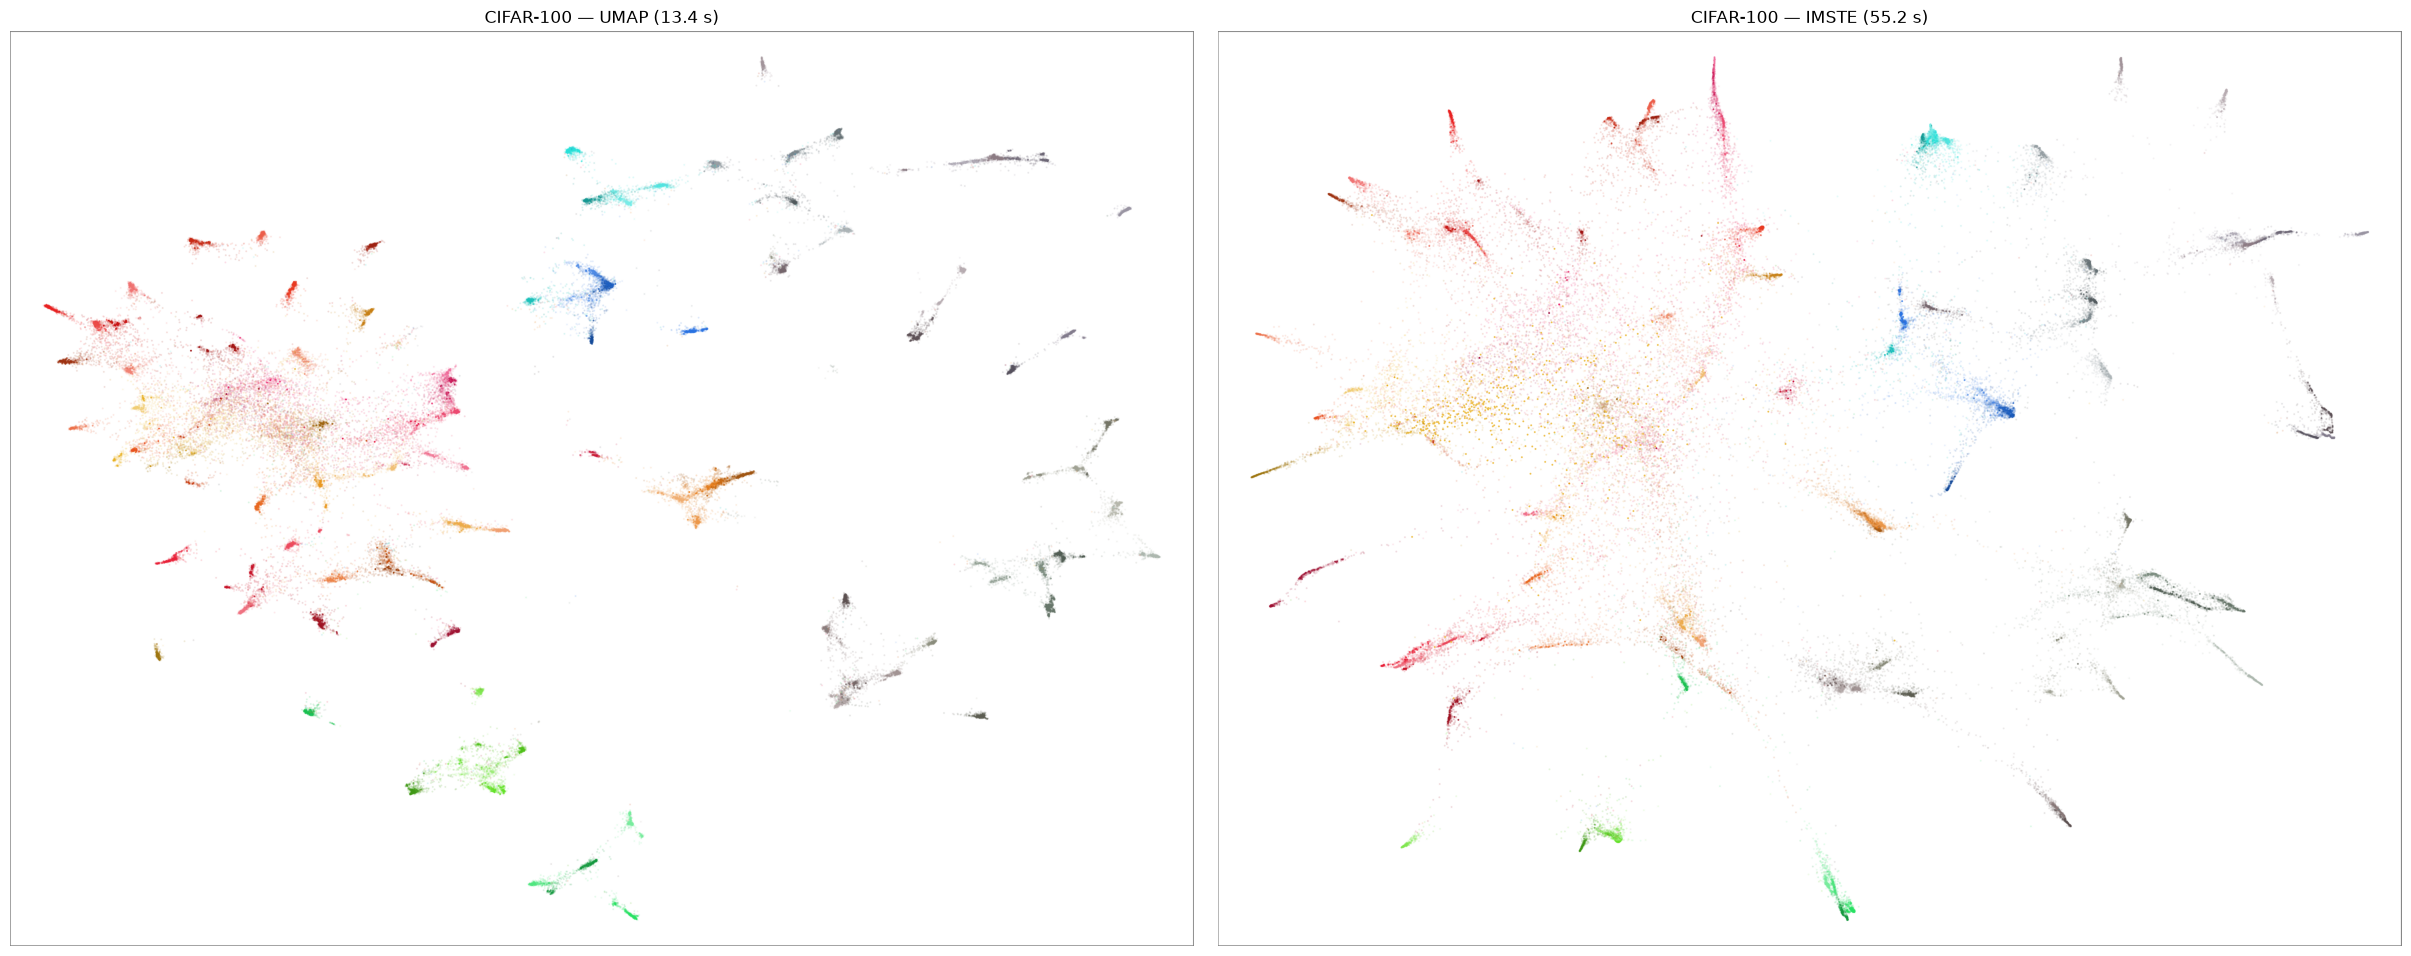

Superclass,Fine class 1,Fine class 2,Fine class 3,Fine class 4,Fine class 5
aquatic_mammals,beaver,dolphin,otter,seal,whale
fish,aquarium_fish,flatfish,ray,shark,trout
flowers,orchid,poppy,rose,sunflower,tulip
food_containers,bottle,bowl,can,cup,plate
fruit_and_vegetables,apple,mushroom,orange,pear,sweet_pepper
household_electrical_devices,clock,keyboard,lamp,telephone,television
household_furniture,bed,chair,couch,table,wardrobe
insects,bee,beetle,butterfly,caterpillar,cockroach
large_carnivores,bear,leopard,lion,tiger,wolf
large_man-made_outdoor_things,bridge,castle,house,road,skyscraper


In [44]:
import colorsys
from html import escape

import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import HTML, display
from PIL import Image as PILImage
from imste.visualization import render_datashader_embedding

LIGHTNESS_LEVELS = (0.34, 0.43, 0.52, 0.61, 0.70)
FAMILY_SATURATION = {"warm": 0.82, "nature": 0.76, "neutral": 0.07}
WARM_SUPERCLASSES = {
    "aquatic_mammals",
    "fish",
    "insects",
    "large_carnivores",
    "large_omnivores_and_herbivores",
    "medium_mammals",
    "non-insect_invertebrates",
    "people",
    "reptiles",
    "small_mammals",
}
NATURE_SUPERCLASSES = {
    "flowers",
    "fruit_and_vegetables",
    "large_natural_outdoor_scenes",
    "trees",
}
NEUTRAL_SUPERCLASSES = {
    "food_containers",
    "household_electrical_devices",
    "household_furniture",
    "large_man-made_outdoor_things",
    "vehicles_1",
    "vehicles_2",
}
SUPERCLASS_FAMILIES = {
    **{name: "warm" for name in WARM_SUPERCLASSES},
    **{name: "nature" for name in NATURE_SUPERCLASSES},
    **{name: "neutral" for name in NEUTRAL_SUPERCLASSES},
}
if set(SUPERCLASS_FAMILIES) != set(coarse_names):
    raise ValueError("Every CIFAR-100 superclass must have exactly one palette family.")

# Related categories share hue ranges; small saturation differences keep gray
# object categories distinct while preserving their neutral appearance.
FAMILY_HUES = {
    "warm": np.linspace(0.94, 1.12, len(WARM_SUPERCLASSES)) % 1.0,
    "nature": np.linspace(0.28, 0.60, len(NATURE_SUPERCLASSES)),
    "neutral": np.linspace(0.00, 0.92, len(NEUTRAL_SUPERCLASSES)),
}
FAMILY_ORDER = {
    "warm": [name for name in coarse_names if name in WARM_SUPERCLASSES],
    "nature": [name for name in coarse_names if name in NATURE_SUPERCLASSES],
    "neutral": [name for name in coarse_names if name in NEUTRAL_SUPERCLASSES],
}
fine_color_key = {}
coarse_color_key = {}
children_by_coarse = {
    coarse_id: np.flatnonzero(fine_to_coarse == coarse_id).tolist()
    for coarse_id in range(len(coarse_names))
}
if any(len(children) != 5 for children in children_by_coarse.values()):
    raise ValueError("Each CIFAR-100 superclass should contain five fine classes.")

for coarse_id, coarse_name in enumerate(coarse_names):
    family = SUPERCLASS_FAMILIES[coarse_name]
    family_index = FAMILY_ORDER[family].index(coarse_name)
    hue = float(FAMILY_HUES[family][family_index])
    saturation = FAMILY_SATURATION[family]
    coarse_color_key[coarse_name] = to_hex(
        colorsys.hls_to_rgb(hue, 0.52, saturation)
    )
    for child_index, fine_id in enumerate(children_by_coarse[coarse_id]):
        fine_color_key[fine_names[fine_id]] = to_hex(
            colorsys.hls_to_rgb(
                hue,
                LIGHTNESS_LEVELS[child_index],
                saturation,
            )
        )

scale = 3
PLOT_WIDTH = int(1100 * scale)
PLOT_HEIGHT = int(850 * scale)

def render_hierarchical_datashader(coordinates):
    coordinates = np.asarray(coordinates)[:, :2]
    coordinate_min = np.nanmin(coordinates, axis=0)
    coordinate_max = np.nanmax(coordinates, axis=0)
    padding = np.maximum((coordinate_max - coordinate_min) * 0.03, 1e-9)
    x_range = (coordinate_min[0] - padding[0], coordinate_max[0] + padding[0])
    y_range = (coordinate_min[1] - padding[1], coordinate_max[1] + padding[1])

    # Render each superclass separately to keep each categorical raster small,
    # then alpha-composite the transparent layers on a shared coordinate frame.
    combined = PILImage.new(
        "RGBA", (PLOT_WIDTH, PLOT_HEIGHT), (255, 255, 255, 255)
    )
    for coarse_id, coarse_name in enumerate(coarse_names):
        group_mask = coarse_labels == coarse_id
        if not np.any(group_mask):
            continue
        group_fine_ids = fine_labels[group_mask]
        group_labels = np.asarray(
            [fine_names[int(label)] for label in group_fine_ids]
        )
        group_color_key = {
            fine_names[fine_id]: fine_color_key[fine_names[fine_id]]
            for fine_id in children_by_coarse[coarse_id]
        }
        layer = render_datashader_embedding(
            coordinates[group_mask],
            group_labels,
            width=PLOT_WIDTH,
            height=PLOT_HEIGHT,
            x_range=x_range,
            y_range=y_range,
            color_key=group_color_key,
            min_alpha=40,
            background=None,
            spread_px=2,
            draw_border=True,
        )
        combined.alpha_composite(layer.to_pil().convert("RGBA"))
    return combined

layouts = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE", Z_imste, imste_seconds + gravity_seconds + mean_shift_seconds),
]
s = 1.5
fig, axes = plt.subplots(1, 2, figsize=(16*s, 8*s), constrained_layout=True)
for ax, (method, coordinates, elapsed) in zip(axes, layouts):
    image = render_hierarchical_datashader(coordinates)
    ax.imshow(image)
    runtime = f"{elapsed / 60:.1f} min" if elapsed >= 60 else f"{elapsed:.1f} s"
    ax.set_title(f"CIFAR-100 — {method} ({runtime})")
    ax.set_axis_off()
plt.show()

# A compact key shows the five fine-class shades under each superclass.
rows = []
for coarse_id, coarse_name in enumerate(coarse_names):
    cells = [
        f'<td style="width:16%;white-space:nowrap;padding:3px 8px;">'
        f'{escape(fine_names[fine_id])}'
        f'<span style="float:right;display:inline-block;width:12px;height:12px;'
        f'background:{fine_color_key[fine_names[fine_id]]}"></span></td>'
        for fine_id in children_by_coarse[coarse_id]
    ]
    coarse_color = coarse_color_key[coarse_name]
    rows.append(
        f'<tr><th style="text-align:left;padding:3px 8px;color:{coarse_color}">'
        f'{escape(coarse_name)}</th>{"".join(cells)}</tr>'
    )
legend_html = (
    '<table style="width:100%;table-layout:fixed;border-collapse:collapse;font:13px sans-serif">'
    '<thead><tr><th style="width:20%">Superclass</th>'
    + "".join(f"<th style=\"width:16%\">Fine class {i + 1}</th>" for i in range(5))
    + "</tr></thead><tbody>"
    + "".join(rows)
    + "</tbody></table>"
)
display(HTML(legend_html))


## Explore the IMSTE layout with Plotly

Hover to inspect both levels of the CIFAR-100 taxonomy. Click a superclass in the legend to show or hide all five of its fine classes.


In [45]:
import plotly.graph_objects as go
from IPython.display import display

Z_plotly = np.asarray(Z_imste)[:, :2]
if len(Z_plotly) != len(fine_labels) or len(Z_plotly) != len(coarse_labels):
    raise ValueError("The IMSTE coordinates and CIFAR-100 labels must have the same number of images.")

fig = go.Figure()
for coarse_id, coarse_name in enumerate(coarse_names):
    coarse_mask = coarse_labels == coarse_id
    fine_ids_in_group = fine_labels[coarse_mask]
    fine_labels_in_group = np.asarray([fine_names[int(label)] for label in fine_ids_in_group])
    point_colors_in_group = np.asarray(
        [fine_color_key[name] for name in fine_labels_in_group]
    )
    customdata = np.column_stack((
        np.full(np.sum(coarse_mask), coarse_name, dtype=object),
        fine_labels_in_group,
    ))
    fig.add_trace(go.Scattergl(
        x=Z_plotly[coarse_mask, 0],
        y=Z_plotly[coarse_mask, 1],
        customdata=customdata,
        mode="markers",
        name=coarse_name,
        legendgroup=f"coarse:{coarse_id}",
        showlegend=False,
        marker={
            "color": point_colors_in_group,
            "size": 4,
            "opacity": 0.75,
            "line": {"width": 0},
        },
        hovertemplate=(
            "Superclass: %{customdata[0]}<br>"
            "Fine class: %{customdata[1]}<extra></extra>"
        ),
    ))
    # The superclass swatch controls visibility for all of its fine-class points.
    fig.add_trace(go.Scattergl(
        x=[None],
        y=[None],
        mode="markers",
        name=coarse_name,
        legendgroup=f"coarse:{coarse_id}",
        marker={"color": coarse_color_key[coarse_name], "size": 14, "symbol": "square"},
        hoverinfo="skip",
    ))

coordinate_min = np.nanmin(Z_plotly, axis=0)
coordinate_max = np.nanmax(Z_plotly, axis=0)
coordinate_padding = np.maximum((coordinate_max - coordinate_min) * 0.03, 1e-9)
x_range = [coordinate_min[0] - coordinate_padding[0], coordinate_max[0] + coordinate_padding[0]]
y_range = [coordinate_min[1] - coordinate_padding[1], coordinate_max[1] + coordinate_padding[1]]
legend_columns_estimate = max(1, 1200 // 150)
legend_rows_estimate = int(np.ceil(len(coarse_names) / legend_columns_estimate))
legend_bottom = max(130, legend_rows_estimate * 26 + 56)
scale = 1.5
fig.update_layout(
    template="plotly_white",
    title="CIFAR-100 IMSTE · hover for fine class · legend toggles superclasses",
    width=1200 * scale,
    height=max(720, 520 + legend_bottom) * scale,
    margin={"l": 20, "r": 20, "t": 70, "b": legend_bottom},
    legend={
        "title": "Superclass",
        "orientation": "h",
        "x": 0.5,
        "y": -0.12,
        "xanchor": "center",
        "yanchor": "top",
        "entrywidth": 150,
        "entrywidthmode": "pixels",
        "groupclick": "togglegroup",
        "itemclick": "toggle",
        "itemdoubleclick": "toggleothers",
        "itemsizing": "constant",
        "itemwidth": 40,
    },
    xaxis={"visible": False, "range": x_range, "autorange": False, "constrain": "domain"},
    yaxis={"visible": False, "range": y_range, "autorange": False, "scaleanchor": "x", "scaleratio": 1, "constrain": "domain"},
    showlegend=True,
)
display(fig)
